In [1]:

# ========================================
# 1. 라이브러리 불러오기
# ========================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ========================================
# 2. 데이터 불러오기
# ========================================

train = pd.read_csv('./data/train.csv')
test = pd.read_csv('./data/test.csv')

# ========================================
# 3. 데이터 기본 정보 확인
# ========================================

# 데이터 크기 확인
print('Train 데이터 크기:', train.shape)
print('Test 데이터 크기:', test.shape)

# 데이터 상위 5개 출력
display(train.head())

# 데이터 타입 확인
train.info()


Train 데이터 크기: (381109, 12)
Test 데이터 크기: (127037, 11)


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
0,1,Male,44,1,28.0,0,> 2 Years,Yes,40454.0,26.0,217,1
1,2,Male,76,1,3.0,0,1-2 Year,No,33536.0,26.0,183,0
2,3,Male,47,1,28.0,0,> 2 Years,Yes,38294.0,26.0,27,1
3,4,Male,21,1,11.0,1,< 1 Year,No,28619.0,152.0,203,0
4,5,Female,29,1,41.0,1,< 1 Year,No,27496.0,152.0,39,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 381109 entries, 0 to 381108
Data columns (total 12 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   id                    381109 non-null  int64  
 1   Gender                381109 non-null  object 
 2   Age                   381109 non-null  int64  
 3   Driving_License       381109 non-null  int64  
 4   Region_Code           381109 non-null  float64
 5   Previously_Insured    381109 non-null  int64  
 6   Vehicle_Age           381109 non-null  object 
 7   Vehicle_Damage        381109 non-null  object 
 8   Annual_Premium        381109 non-null  float64
 9   Policy_Sales_Channel  381109 non-null  float64
 10  Vintage               381109 non-null  int64  
 11  Response              381109 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 34.9+ MB


In [2]:

# ========================================
# 4. 데이터 기초 탐색 (EDA)
# ========================================

# 기초 통계량 확인
display(train.describe(include='all'))

# 결측치 확인
print('Train 결측치')
print(train.isnull().sum())

print('Test 결측치')
print(test.isnull().sum())

# 중복 데이터 확인
print('Train 중복 행:', train.duplicated().sum())
print('Test 중복 행:', test.duplicated().sum())

# 예측 대상(Response)의 고객 수 확인
print('Response별 고객 수')
print(train['Response'].value_counts())

# Response별 고객 비율 확인
print('Response별 비율')
print(train['Response'].value_counts(normalize=True))


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
count,381109.000000,381109,381109.000000,381109.000000,381109.000000,381109.000000,381109,381109,381109.000000,381109.000000,381109.000000,381109.000000
unique,NaN,2,NaN,NaN,NaN,NaN,3,2,NaN,NaN,NaN,NaN
top,NaN,Male,NaN,NaN,NaN,NaN,1-2 Year,Yes,NaN,NaN,NaN,NaN
freq,NaN,206089,NaN,NaN,NaN,NaN,200316,192413,NaN,NaN,NaN,NaN
mean,190555.000000,NaN,38.822584,0.997869,26.388807,0.458210,NaN,NaN,30564.389581,112.034295,154.347397,0.122563
std,110016.836208,NaN,15.511611,0.046110,13.229888,0.498251,NaN,NaN,17213.155057,54.203995,83.671304,0.327936
min,1.000000,NaN,20.000000,0.000000,0.000000,0.000000,NaN,NaN,2630.000000,1.000000,10.000000,0.000000
25%,95278.000000,NaN,25.000000,1.000000,15.000000,0.000000,NaN,NaN,24405.000000,29.000000,82.000000,0.000000
50%,190555.000000,NaN,36.000000,1.000000,28.000000,0.000000,NaN,NaN,31669.000000,133.000000,154.000000,0.000000
75%,285832.000000,NaN,49.000000,1.000000,35.000000,1.000000,NaN,NaN,39400.000000,152.000000,227.000000,0.000000


Train 결측치
id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
Response                0
dtype: int64
Test 결측치
id                      0
Gender                  0
Age                     0
Driving_License         0
Region_Code             0
Previously_Insured      0
Vehicle_Age             0
Vehicle_Damage          0
Annual_Premium          0
Policy_Sales_Channel    0
Vintage                 0
dtype: int64
Train 중복 행: 0
Test 중복 행: 0
Response별 고객 수
0    334399
1     46710
Name: Response, dtype: int64
Response별 비율
0    0.877437
1    0.122563
Name: Response, dtype: float64


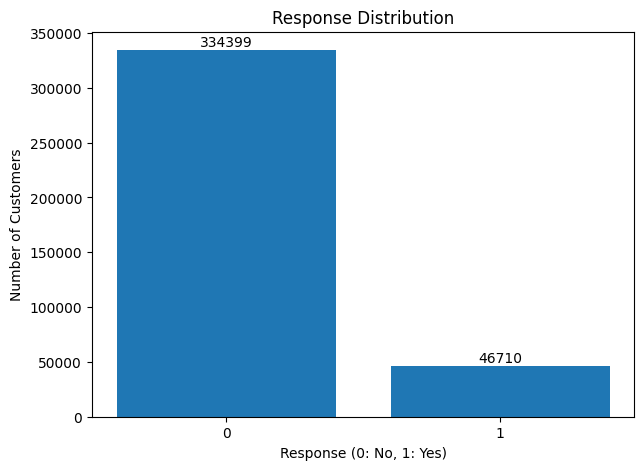

Response별 고객 비율 (%)
0    87.743664
1    12.256336
Name: Response, dtype: float64


In [3]:

# ========================================
# 5. Response 클래스 분포 시각화
# ========================================

# Response별 고객 수 계산
response_count = train['Response'].value_counts().sort_index()

# 그래프 크기 설정
plt.figure(figsize=(7, 5))

# Response별 고객 수 막대그래프
plt.bar(response_count.index, response_count.values)

# 그래프 제목과 축 이름
plt.title('Response Distribution')
plt.xlabel('Response (0: No, 1: Yes)')
plt.ylabel('Number of Customers')

# X축 눈금을 0과 1로 설정
plt.xticks([0, 1])

# 막대 위에 실제 고객 수 표시
for i, count in enumerate(response_count.values):
    plt.text(i, count + 3000, str(count), ha='center')

# 그래프 출력
plt.show()

# Response별 고객 비율 출력
print('Response별 고객 비율 (%)')
print(train['Response'].value_counts(normalize=True).sort_index() * 100)


In [4]:

# ========================================
# 6. Train / Validation / Holdout 분할
# ========================================

from sklearn.model_selection import train_test_split

# 전체 데이터를 우선 Train 80%, Holdout 20%로 분리
train_data, holdout_data = train_test_split(
    train,
    test_size=0.2,
    random_state=42,
    stratify=train['Response']
)

# Train 80%를 다시 Train 60%, Validation 20%로 분리
train_data, valid_data = train_test_split(
    train_data,
    test_size=0.25,
    random_state=42,
    stratify=train_data['Response']
)

# 분할된 데이터 크기 확인
print('Train 크기:', train_data.shape)
print('Validation 크기:', valid_data.shape)
print('Holdout 크기:', holdout_data.shape)

# 데이터별 Response=1 비율 확인
print('Train 관심률:', train_data['Response'].mean())
print('Validation 관심률:', valid_data['Response'].mean())
print('Holdout 관심률:', holdout_data['Response'].mean())


Train 크기: (228665, 12)
Validation 크기: (76222, 12)
Holdout 크기: (76222, 12)
Train 관심률: 0.12256357553626485
Validation 관심률: 0.12256303954238934
Holdout 관심률: 0.12256303954238934



 Gender
Gender
Female    10.472773
Male      13.765045
Name: Response, dtype: float64


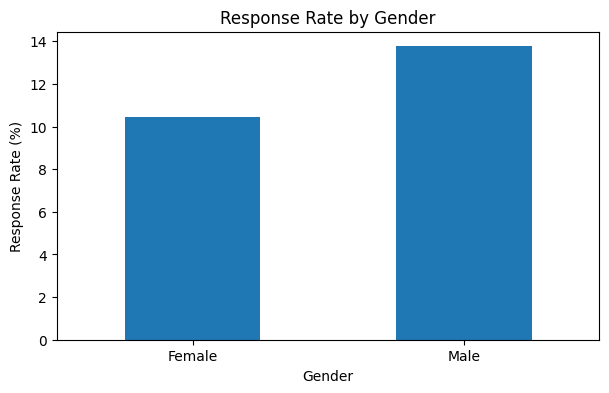


 Previously_Insured
Previously_Insured
0    22.556737
1     0.083012
Name: Response, dtype: float64


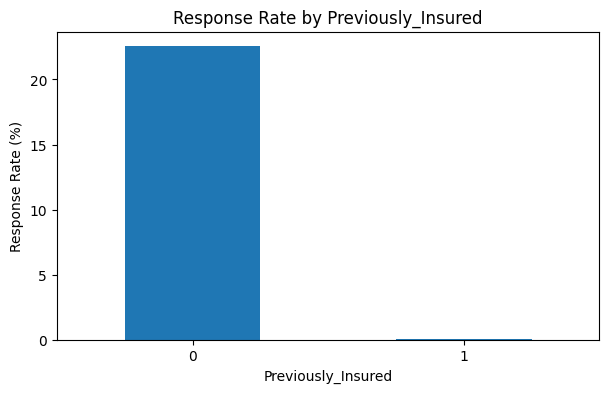


 Vehicle_Age
Vehicle_Age
1-2 Year     17.368207
< 1 Year      4.350028
> 2 Years    29.379524
Name: Response, dtype: float64


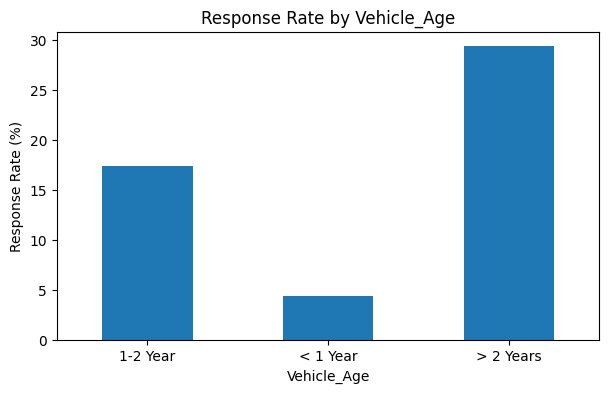


 Vehicle_Damage
Vehicle_Damage
No      0.539776
Yes    23.742098
Name: Response, dtype: float64


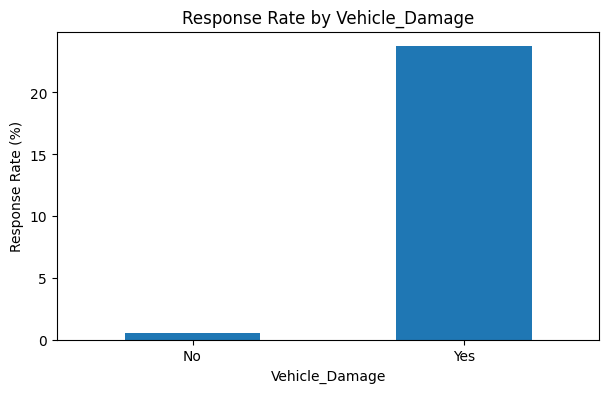

In [5]:

# ========================================
# 7. 범주형 변수별 보험 관심률 분석
# ========================================

# 분석할 변수 목록
columns = [
    'Gender',
    'Previously_Insured',
    'Vehicle_Age',
    'Vehicle_Damage'
]

# 변수별 보험 관심률 계산 및 시각화
for col in columns:

    # 변수의 값별 Response 평균 계산
    response_rate = train_data.groupby(col)['Response'].mean() * 100

    # 분석 결과 출력
    print('\n', col)
    print(response_rate)

    # 막대그래프 생성
    plt.figure(figsize=(7, 4))
    response_rate.plot(kind='bar')

    # 제목 및 축 이름 설정
    plt.title('Response Rate by ' + col)
    plt.xlabel(col)
    plt.ylabel('Response Rate (%)')
    plt.xticks(rotation=0)

    # 그래프 출력
    plt.show()


In [6]:

# ========================================
# 8-1. 수치형 변수 기초 통계량
# ========================================

# 분석할 수치형 변수
numeric_cols = ['Age', 'Annual_Premium', 'Vintage']

# 학습 데이터의 기초 통계량 확인
display(train_data[numeric_cols].describe())


,Age,Annual_Premium,Vintage
count,228665.000000,228665.000000,228665.000000
mean,38.857613,30593.568482,154.525651
std,15.529071,17296.033771,83.705670
min,20.000000,2630.000000,10.000000
25%,25.000000,24404.000000,82.000000
50%,36.000000,31688.000000,154.000000
75%,49.000000,39430.000000,227.000000
max,85.000000,540165.000000,299.000000


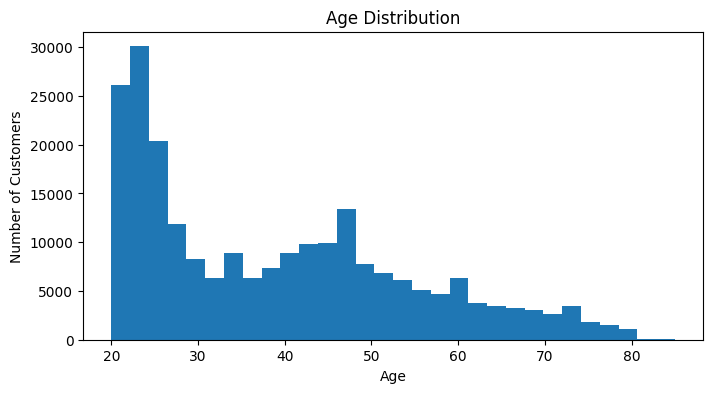

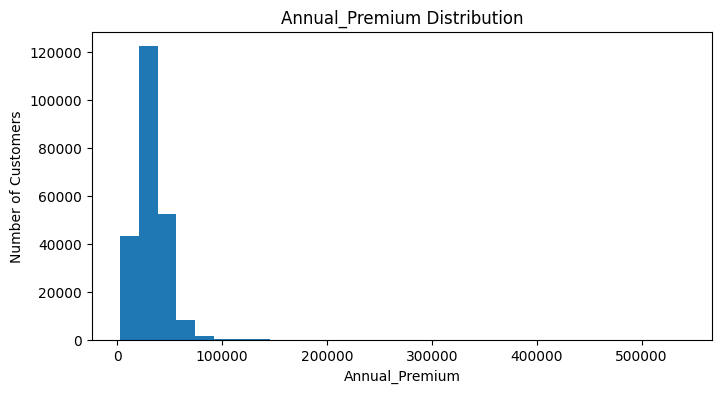

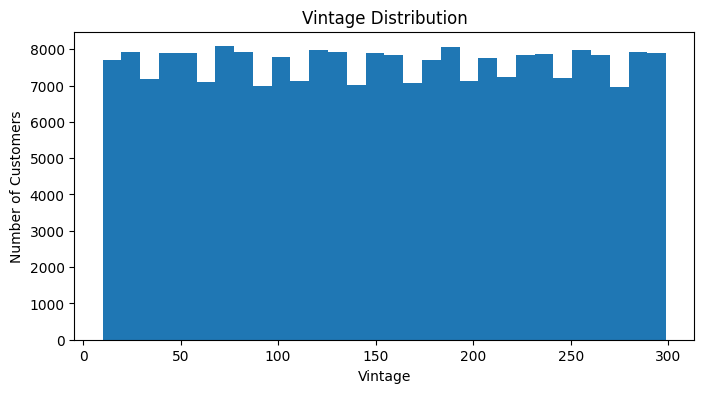

In [7]:

# ========================================
# 8-2. 수치형 변수 히스토그램
# ========================================

# 수치형 변수 3개의 분포 시각화
for col in numeric_cols:

    # 그래프 크기 설정
    plt.figure(figsize=(8, 4))

    # 히스토그램 생성
    plt.hist(train_data[col], bins=30)

    # 그래프 제목과 축 이름 설정
    plt.title(col + ' Distribution')
    plt.xlabel(col)
    plt.ylabel('Number of Customers')

    # 그래프 출력
    plt.show()


In [8]:

# ========================================
# 9. Annual_Premium 이상치 분석
# ========================================

# 보험료 기초 통계량 출력
print(train_data['Annual_Premium'].describe())

# 보험료가 10,000 미만인 고객 확인
low_premium = train_data[train_data['Annual_Premium'] < 10000]

print('10,000 미만 고객 수:', len(low_premium))
print(low_premium['Annual_Premium'].value_counts().sort_index())

# IQR 계산
Q1 = train_data['Annual_Premium'].quantile(0.25)
Q3 = train_data['Annual_Premium'].quantile(0.75)

IQR = Q3 - Q1

# 이상치 판단 기준
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

print('이상치 하한값:', lower_bound)
print('이상치 상한값:', upper_bound)

# 이상치 후보 확인
outliers = train_data[
    (train_data['Annual_Premium'] < lower_bound) |
    (train_data['Annual_Premium'] > upper_bound)
]

print('이상치 후보 수:', len(outliers))
print('이상치 후보 비율(%):', len(outliers) / len(train_data) * 100)


count    228665.000000
mean      30593.568482
std       17296.033771
min        2630.000000
25%       24404.000000
50%       31688.000000
75%       39430.000000
max      540165.000000
Name: Annual_Premium, dtype: float64
10,000 미만 고객 수: 38915
2630.0    38912
6098.0        1
7670.0        1
9792.0        1
Name: Annual_Premium, dtype: int64
이상치 하한값: 1865.0
이상치 상한값: 61969.0
이상치 후보 수: 6260
이상치 후보 비율(%): 2.737629283012267


In [9]:

# ========================================
# 10. 문자형 데이터 정수형 변환
# ========================================

# 원본 데이터 보존을 위해 복사
train_pre = train_data.copy()
valid_pre = valid_data.copy()
holdout_pre = holdout_data.copy()
test_pre = test.copy()

# 변환할 컬럼과 숫자 지정
gender_map = {'Male': 1, 'Female': 2}

vehicle_age_map = {
    '< 1 Year': 1,
    '1-2 Year': 2,
    '> 2 Years': 3
}

damage_map = {'No': 0, 'Yes': 1}

# 학습 데이터 변환
train_pre['Gender'] = train_pre['Gender'].map(gender_map)
train_pre['Vehicle_Age'] = train_pre['Vehicle_Age'].map(vehicle_age_map)
train_pre['Vehicle_Damage'] = train_pre['Vehicle_Damage'].map(damage_map)

# 검증 데이터 변환
valid_pre['Gender'] = valid_pre['Gender'].map(gender_map)
valid_pre['Vehicle_Age'] = valid_pre['Vehicle_Age'].map(vehicle_age_map)
valid_pre['Vehicle_Damage'] = valid_pre['Vehicle_Damage'].map(damage_map)

# 최종 평가 데이터 변환
holdout_pre['Gender'] = holdout_pre['Gender'].map(gender_map)
holdout_pre['Vehicle_Age'] = holdout_pre['Vehicle_Age'].map(vehicle_age_map)
holdout_pre['Vehicle_Damage'] = holdout_pre['Vehicle_Damage'].map(damage_map)

# 공식 테스트 데이터 변환
test_pre['Gender'] = test_pre['Gender'].map(gender_map)
test_pre['Vehicle_Age'] = test_pre['Vehicle_Age'].map(vehicle_age_map)
test_pre['Vehicle_Damage'] = test_pre['Vehicle_Damage'].map(damage_map)

# ========================================
# 변환 결과 확인
# ========================================

# 변환된 데이터 상위 5개 확인
display(train_pre.head())

# 변환된 3개 컬럼의 데이터 타입 확인
print(train_pre[['Gender', 'Vehicle_Age', 'Vehicle_Damage']].dtypes)

# 변환된 값 확인
print('Gender:', train_pre['Gender'].unique())
print('Vehicle_Age:', train_pre['Vehicle_Age'].unique())
print('Vehicle_Damage:', train_pre['Vehicle_Damage'].unique())

# 데이터별 결측치 확인
print('Train 결측치:', train_pre.isnull().sum().sum())
print('Validation 결측치:', valid_pre.isnull().sum().sum())
print('Holdout 결측치:', holdout_pre.isnull().sum().sum())
print('Test 결측치:', test_pre.isnull().sum().sum())


,id,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage,Response
257796,257797,1,45,1,41.0,0,2,1,33056.0,124.0,128,1
224511,224512,2,37,1,28.0,1,2,0,25765.0,152.0,162,0
15821,15822,1,68,1,20.0,0,2,0,2630.0,124.0,36,0
179652,179653,2,24,1,8.0,0,1,1,31659.0,152.0,292,0
376338,376339,1,30,1,6.0,0,2,1,27221.0,154.0,111,0


Gender            int64
Vehicle_Age       int64
Vehicle_Damage    int64
dtype: object
Gender: [1 2]
Vehicle_Age: [2 1 3]
Vehicle_Damage: [1 0]
Train 결측치: 0
Validation 결측치: 0
Holdout 결측치: 0
Test 결측치: 0


In [10]:

# ========================================
# 11. 입력 변수(X)와 정답(y) 분리
# ========================================

# 모델 학습에 사용하지 않을 컬럼
drop_cols = ['id', 'Response']

# 학습 데이터
X_train = train_pre.drop(columns=drop_cols)
y_train = train_pre['Response']

# 검증 데이터
X_valid = valid_pre.drop(columns=drop_cols)
y_valid = valid_pre['Response']

# 입력 데이터 크기 확인
print('X_train:', X_train.shape)
print('y_train:', y_train.shape)

print('X_valid:', X_valid.shape)
print('y_valid:', y_valid.shape)

# 모델 입력 변수 확인
print('사용할 입력 변수:')
print(X_train.columns.tolist())

# 데이터 상위 5개 확인
display(X_train.head())


X_train: (228665, 10)
y_train: (228665,)
X_valid: (76222, 10)
y_valid: (76222,)
사용할 입력 변수:
['Gender', 'Age', 'Driving_License', 'Region_Code', 'Previously_Insured', 'Vehicle_Age', 'Vehicle_Damage', 'Annual_Premium', 'Policy_Sales_Channel', 'Vintage']


,Gender,Age,Driving_License,Region_Code,Previously_Insured,Vehicle_Age,Vehicle_Damage,Annual_Premium,Policy_Sales_Channel,Vintage
257796,1,45,1,41.0,0,2,1,33056.0,124.0,128
224511,2,37,1,28.0,1,2,0,25765.0,152.0,162
15821,1,68,1,20.0,0,2,0,2630.0,124.0,36
179652,2,24,1,8.0,0,1,1,31659.0,152.0,292
376338,1,30,1,6.0,0,2,1,27221.0,154.0,111


In [11]:

# ========================================
# 12. Decision Tree 베이스라인 모델
# ========================================

# 결정트리 모델 불러오기
from sklearn.tree import DecisionTreeClassifier

# ROC-AUC 평가 함수 불러오기
from sklearn.metrics import roc_auc_score

# 결정트리 모델 생성
dt_model = DecisionTreeClassifier(random_state=42)

# 학습 데이터로 모델 학습
dt_model.fit(X_train, y_train)

# 학습 데이터의 Response=1 예측 확률
train_proba = dt_model.predict_proba(X_train)[:, 1]

# 검증 데이터의 Response=1 예측 확률
valid_proba = dt_model.predict_proba(X_valid)[:, 1]

# ROC-AUC 계산
train_auc = roc_auc_score(y_train, train_proba)
valid_auc = roc_auc_score(y_valid, valid_proba)

# 평가 결과 출력
print('Train ROC-AUC:', round(train_auc, 6))
print('Validation ROC-AUC:', round(valid_auc, 6))

# 학습과 검증 점수 차이
print('ROC-AUC 차이:', round(train_auc - valid_auc, 6))

# 결정트리의 깊이와 리프 노드 수 확인
print('트리 깊이:', dt_model.get_depth())
print('리프 노드 수:', dt_model.get_n_leaves())


Train ROC-AUC: 1.0
Validation ROC-AUC: 0.603082
ROC-AUC 차이: 0.396918
트리 깊이: 73
리프 노드 수: 30444


In [12]:

# ========================================
# 13. 결정트리 깊이별 ROC-AUC 비교
# ========================================

# 실험할 트리 최대 깊이
depth_list = [3, 5, 7, 10, 15]

# 각 실험의 결과를 저장할 리스트
depth_results = []

# 트리 깊이를 하나씩 변경하며 학습
for depth in depth_list:

    # 최대 깊이를 제한한 결정트리 생성
    model = DecisionTreeClassifier(
        max_depth=depth,
        random_state=42
    )

    # 모델 학습
    model.fit(X_train, y_train)

    # 학습 데이터의 관심 확률 예측
    train_pred = model.predict_proba(X_train)[:, 1]

    # 검증 데이터의 관심 확률 예측
    valid_pred = model.predict_proba(X_valid)[:, 1]

    # ROC-AUC 계산
    train_score = roc_auc_score(y_train, train_pred)
    valid_score = roc_auc_score(y_valid, valid_pred)

    # 결과 저장
    depth_results.append([
        depth,
        train_score,
        valid_score,
        train_score - valid_score
    ])

# 결과를 DataFrame으로 변환
depth_df = pd.DataFrame(
    depth_results,
    columns=['max_depth', 'Train_AUC', 'Validation_AUC', 'AUC_Gap']
)

# 결과 출력
display(depth_df)


,max_depth,Train_AUC,Validation_AUC,AUC_Gap
0,3,0.817236,0.815986,0.001250
1,5,0.839277,0.837542,0.001735
2,7,0.846900,0.844504,0.002395
3,10,0.859383,0.847730,0.011653
4,15,0.887408,0.828722,0.058686


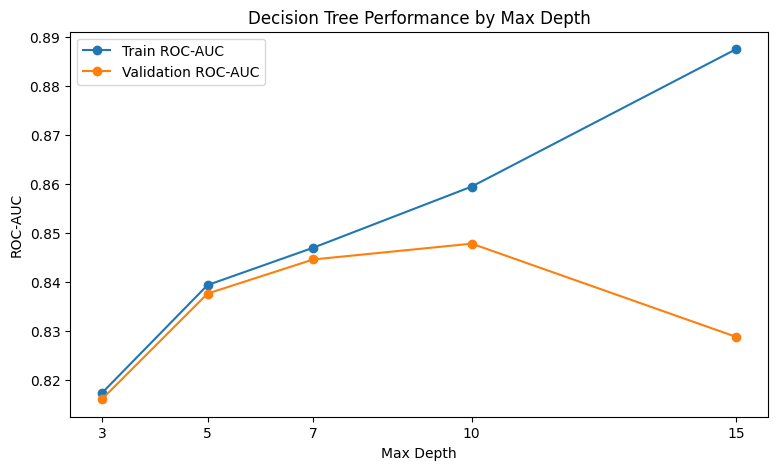

In [13]:

# ========================================
# 13-1. 결정트리 깊이별 성능 시각화
# ========================================

plt.figure(figsize=(9, 5))

# 학습 데이터 ROC-AUC
plt.plot(
    depth_df['max_depth'],
    depth_df['Train_AUC'],
    marker='o',
    label='Train ROC-AUC'
)

# 검증 데이터 ROC-AUC
plt.plot(
    depth_df['max_depth'],
    depth_df['Validation_AUC'],
    marker='o',
    label='Validation ROC-AUC'
)

# 그래프 제목 및 축 설정
plt.title('Decision Tree Performance by Max Depth')
plt.xlabel('Max Depth')
plt.ylabel('ROC-AUC')
plt.xticks(depth_list)

# 범례 표시
plt.legend()

# 그래프 출력
plt.show()


In [14]:

# ========================================
# 14. 개선된 Decision Tree 모델
# ========================================

# 검증 성능이 가장 높은 깊이 10 적용
dt_best = DecisionTreeClassifier(
    max_depth=10,
    random_state=42
)

# 학습 데이터로 모델 학습
dt_best.fit(X_train, y_train)

# 검증 데이터의 관심 확률 예측
dt_best_proba = dt_best.predict_proba(X_valid)[:, 1]

# ROC-AUC 계산
dt_best_auc = roc_auc_score(y_valid, dt_best_proba)

print('개선된 Decision Tree ROC-AUC:', round(dt_best_auc, 6))


개선된 Decision Tree ROC-AUC: 0.84773


In [15]:

# ========================================
# 15. Random Forest 모델 학습
# ========================================

# 랜덤포레스트 모델 불러오기
from sklearn.ensemble import RandomForestClassifier

# 랜덤포레스트 모델 생성
rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

# 모델 학습
rf_model.fit(X_train, y_train)

# 학습 데이터 예측 확률
rf_train_proba = rf_model.predict_proba(X_train)[:, 1]

# 검증 데이터 예측 확률
rf_valid_proba = rf_model.predict_proba(X_valid)[:, 1]

# ROC-AUC 계산
rf_train_auc = roc_auc_score(y_train, rf_train_proba)
rf_valid_auc = roc_auc_score(y_valid, rf_valid_proba)

# 결과 출력
print('Random Forest Train ROC-AUC:', round(rf_train_auc, 6))
print('Random Forest Validation ROC-AUC:', round(rf_valid_auc, 6))
print('ROC-AUC 차이:', round(rf_train_auc - rf_valid_auc, 6))


Random Forest Train ROC-AUC: 0.865373
Random Forest Validation ROC-AUC: 0.854373
ROC-AUC 차이: 0.011


In [16]:

# ========================================
# 16. XGBoost 모델 학습
# ========================================

# XGBoost 라이브러리 불러오기
from xgboost import XGBClassifier

# XGBoost 모델 생성
xgb_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

# 학습 데이터로 모델 학습
xgb_model.fit(X_train, y_train)

# 학습 데이터 예측 확률
xgb_train_proba = xgb_model.predict_proba(X_train)[:, 1]

# 검증 데이터 예측 확률
xgb_valid_proba = xgb_model.predict_proba(X_valid)[:, 1]

# ROC-AUC 계산
xgb_train_auc = roc_auc_score(y_train, xgb_train_proba)
xgb_valid_auc = roc_auc_score(y_valid, xgb_valid_proba)

# 평가 결과 출력
print('XGBoost Train ROC-AUC:', round(xgb_train_auc, 6))
print('XGBoost Validation ROC-AUC:', round(xgb_valid_auc, 6))
print('ROC-AUC 차이:', round(xgb_train_auc - xgb_valid_auc, 6))


XGBoost Train ROC-AUC: 0.860796
XGBoost Validation ROC-AUC: 0.857758
ROC-AUC 차이: 0.003038


In [17]:

# ========================================
# 17. 모델별 ROC-AUC 비교
# ========================================

model_results = pd.DataFrame({
    'Model': [
        'Decision Tree (Baseline)',
        'Decision Tree (Depth 10)',
        'Random Forest',
        'XGBoost'
    ],
    'Train_AUC': [
        train_auc,
        depth_df.loc[depth_df['max_depth'] == 10, 'Train_AUC'].iloc[0],
        rf_train_auc,
        xgb_train_auc
    ],
    'Validation_AUC': [
        valid_auc,
        dt_best_auc,
        rf_valid_auc,
        xgb_valid_auc
    ]
})

# 검증 성능 높은 순서대로 정렬
model_results = model_results.sort_values(
    by='Validation_AUC',
    ascending=False
)

display(model_results)


,Model,Train_AUC,Validation_AUC
3,XGBoost,0.860796,0.857758
2,Random Forest,0.865373,0.854373
1,Decision Tree (Depth 10),0.859383,0.847730
0,Decision Tree (Baseline),1.000000,0.603082


In [18]:

# ========================================
# 18. 5-Fold 교차검증
# ========================================

# 교차검증 함수 불러오기
from sklearn.model_selection import StratifiedKFold, cross_val_score

# 클래스 비율을 유지하는 5-Fold 설정
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# 비교할 모델
cv_models = {
    'Decision Tree': DecisionTreeClassifier(
        max_depth=10,
        random_state=42
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=100,
        max_depth=5,
        learning_rate=0.1,
        random_state=42,
        eval_metric='logloss',
        n_jobs=-1
    )
}

# 결과 저장 리스트
cv_results = []

# 각 모델별 교차검증
for name, model in cv_models.items():

    print(name, '교차검증 시작')

    # ROC-AUC 기준으로 5번 평가
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=skf,
        scoring='roc_auc',
        n_jobs=1
    )

    # 평균 및 표준편차 저장
    cv_results.append([
        name,
        scores.mean(),
        scores.std()
    ])

    print('Fold별 ROC-AUC:', scores)
    print('평균 ROC-AUC:', round(scores.mean(), 6))
    print('표준편차:', round(scores.std(), 6))
    print()

# DataFrame으로 정리
cv_df = pd.DataFrame(
    cv_results,
    columns=['Model', 'CV_Mean_AUC', 'CV_Std_AUC']
)

# 평균 점수가 높은 순서대로 정렬
cv_df = cv_df.sort_values(
    by='CV_Mean_AUC',
    ascending=False
)

display(cv_df)


Decision Tree 교차검증 시작
Fold별 ROC-AUC: [0.84475606 0.84750108 0.84397878 0.84550215 0.84874148]
평균 ROC-AUC: 0.846096
표준편차: 0.001767

Random Forest 교차검증 시작
Fold별 ROC-AUC: [0.85288457 0.85681479 0.85345002 0.85393729 0.8565958 ]
평균 ROC-AUC: 0.854736
표준편차: 0.001643

XGBoost 교차검증 시작
Fold별 ROC-AUC: [0.8551127  0.85833788 0.85514247 0.85554938 0.85878163]
평균 ROC-AUC: 0.856585
표준편차: 0.001626



,Model,CV_Mean_AUC,CV_Std_AUC
2,XGBoost,0.856585,0.001626
1,Random Forest,0.854736,0.001643
0,Decision Tree,0.846096,0.001767


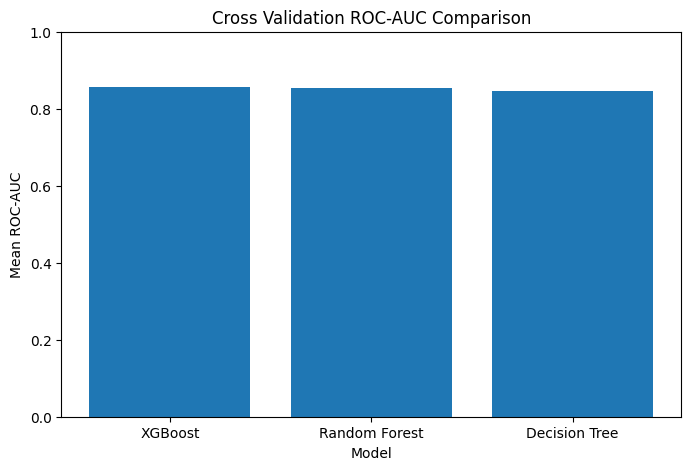

In [19]:

# ========================================
# 19. 모델별 교차검증 결과 시각화
# ========================================

plt.figure(figsize=(8, 5))

# 모델별 평균 ROC-AUC 막대그래프
plt.bar(
    cv_df['Model'],
    cv_df['CV_Mean_AUC']
)

# 제목과 축 이름 설정
plt.title('Cross Validation ROC-AUC Comparison')
plt.xlabel('Model')
plt.ylabel('Mean ROC-AUC')
plt.ylim(0, 1)

# 그래프 출력
plt.show()


In [20]:

# ========================================
# 21. XGBoost 하이퍼파라미터 튜닝
# ========================================

# GridSearchCV 불러오기
from sklearn.model_selection import GridSearchCV

# 튜닝할 XGBoost 모델 생성
xgb_tuning = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    n_jobs=4
)

# 탐색할 하이퍼파라미터 설정
param_grid = {
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1],
    'n_estimators': [100, 200]
}

# GridSearchCV 설정
grid_search = GridSearchCV(
    estimator=xgb_tuning,
    param_grid=param_grid,
    scoring='roc_auc',
    cv=3,
    n_jobs=1,
    verbose=1
)

# 학습 데이터에서만 튜닝 진행
grid_search.fit(X_train, y_train)

# 최적 파라미터 출력
print('최적 파라미터:', grid_search.best_params_)

# 최적 교차검증 ROC-AUC 출력
print('최적 CV ROC-AUC:', round(grid_search.best_score_, 6))

# 최적 모델 저장
xgb_best = grid_search.best_estimator_

# 검증 데이터 예측 확률 계산
xgb_best_proba = xgb_best.predict_proba(X_valid)[:, 1]

# Validation ROC-AUC 계산
xgb_best_valid_auc = roc_auc_score(y_valid, xgb_best_proba)

print('튜닝 후 Validation ROC-AUC:', round(xgb_best_valid_auc, 6))


Fitting 3 folds for each of 8 candidates, totalling 24 fits
최적 파라미터: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200}
최적 CV ROC-AUC: 0.856407
튜닝 후 Validation ROC-AUC: 0.858165


In [21]:

# ========================================
# 22. XGBoost 튜닝 전후 비교
# ========================================

# 기존 XGBoost 검증 성능과 튜닝 후 성능 비교
tuning_result = pd.DataFrame({
    'Model': ['XGBoost Before Tuning', 'XGBoost After Tuning'],
    'Validation_AUC': [xgb_valid_auc, xgb_best_valid_auc]
})

# 결과 출력
display(tuning_result)

# ROC-AUC 변화 확인
print(
    'ROC-AUC 변화:',
    round(xgb_best_valid_auc - xgb_valid_auc, 6)
)


,Model,Validation_AUC
0,XGBoost Before Tuning,0.857758
1,XGBoost After Tuning,0.858165


ROC-AUC 변화: 0.000407


In [22]:

# ========================================
# 23. 최종 XGBoost 모델 재학습
# ========================================

# Train과 Validation 데이터 합치기
X_train_final = pd.concat([X_train, X_valid])
y_train_final = pd.concat([y_train, y_valid])

# 최종 모델 생성 (기존 XGBoost 설정 유지)
final_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

# 합친 데이터로 모델 학습
final_model.fit(X_train_final, y_train_final)

print('최종 학습 데이터 크기:', X_train_final.shape)
print('최종 모델 학습 완료')


최종 학습 데이터 크기: (304887, 10)
최종 모델 학습 완료


In [23]:

# ========================================
# 24. Holdout 데이터 최종 평가
# ========================================

# Holdout 입력 변수와 정답 분리
X_holdout = holdout_pre.drop(columns=['id', 'Response'])
y_holdout = holdout_pre['Response']

# 최종 모델로 예측
holdout_pred = final_model.predict(X_holdout)

# Response=1 예측 확률
holdout_proba = final_model.predict_proba(X_holdout)[:, 1]

# 평가 함수 불러오기
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# 성능 평가
print('Holdout Accuracy:', round(accuracy_score(y_holdout, holdout_pred), 6))
print('Holdout Precision:', round(precision_score(y_holdout, holdout_pred, zero_division=0), 6))
print('Holdout Recall:', round(recall_score(y_holdout, holdout_pred, zero_division=0), 6))
print('Holdout F1-score:', round(f1_score(y_holdout, holdout_pred, zero_division=0), 6))
print('Holdout ROC-AUC:', round(roc_auc_score(y_holdout, holdout_proba), 6))

# 혼동행렬 출력
print('\nConfusion Matrix')
print(confusion_matrix(y_holdout, holdout_pred))

# 분류 결과 상세 출력
print('\nClassification Report')
print(classification_report(y_holdout, holdout_pred, zero_division=0))


Holdout Accuracy: 0.877542
Holdout Precision: 0.666667
Holdout Recall: 0.001713
Holdout F1-score: 0.003417
Holdout ROC-AUC: 0.857677

Confusion Matrix
[[66872     8]
 [ 9326    16]]

Classification Report
              precision    recall  f1-score   support

           0       0.88      1.00      0.93     66880
           1       0.67      0.00      0.00      9342

    accuracy                           0.88     76222
   macro avg       0.77      0.50      0.47     76222
weighted avg       0.85      0.88      0.82     76222



In [24]:

# ========================================
# 25. Validation 데이터 임계값별 성능 비교
# ========================================

# 기존 XGBoost는 Train 데이터만 학습한 모델
# Validation 데이터의 관심 확률 예측
valid_probability = xgb_model.predict_proba(X_valid)[:, 1]

# 비교할 분류 임계값
thresholds = [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]

# 결과 저장
threshold_results = []

# 임계값별 예측 및 성능 평가
for threshold in thresholds:

    # 임계값 이상이면 관심 고객(1)으로 분류
    pred = (valid_probability >= threshold).astype(int)

    # 평가 지표 계산
    precision = precision_score(y_valid, pred, zero_division=0)
    recall = recall_score(y_valid, pred, zero_division=0)
    f1 = f1_score(y_valid, pred, zero_division=0)

    # 결과 저장
    threshold_results.append([
        threshold,
        precision,
        recall,
        f1,
        pred.sum()
    ])

# DataFrame 생성
threshold_df = pd.DataFrame(
    threshold_results,
    columns=[
        'Threshold',
        'Precision',
        'Recall',
        'F1_score',
        'Predicted_Positive'
    ]
)

display(threshold_df)


,Threshold,Precision,Recall,F1_score,Predicted_Positive
0,0.10,0.267898,0.958146,0.418721,33412
1,0.15,0.291916,0.894027,0.440123,28611
2,0.20,0.312673,0.820809,0.452844,24524
3,0.25,0.335847,0.729501,0.459945,20292
4,0.30,0.365451,0.544851,0.437473,13928
5,0.40,0.457636,0.090773,0.151496,1853
6,0.50,0.583333,0.001499,0.002990,24


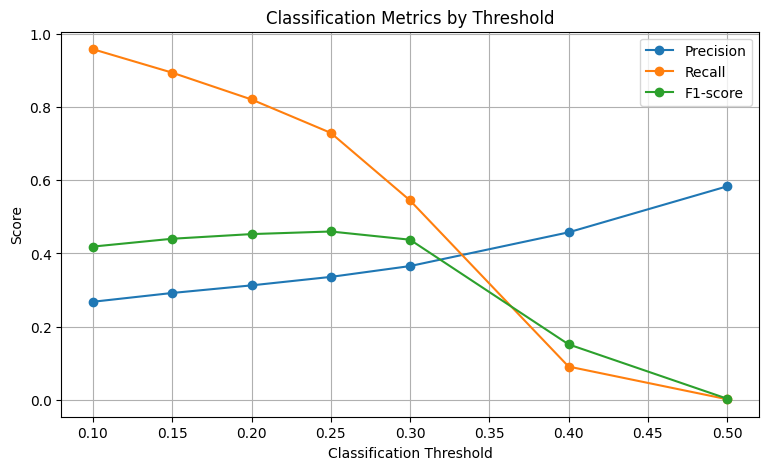

In [25]:

# ========================================
# 26. 임계값별 성능 그래프
# ========================================

plt.figure(figsize=(9, 5))

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Precision'],
    marker='o',
    label='Precision'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['Recall'],
    marker='o',
    label='Recall'
)

plt.plot(
    threshold_df['Threshold'],
    threshold_df['F1_score'],
    marker='o',
    label='F1-score'
)

plt.title('Classification Metrics by Threshold')
plt.xlabel('Classification Threshold')
plt.ylabel('Score')
plt.legend()
plt.grid(True)
plt.show()


,Feature,Importance
6,Vehicle_Damage,0.595960
4,Previously_Insured,0.336509
1,Age,0.031729
5,Vehicle_Age,0.008980
8,Policy_Sales_Channel,0.008896
3,Region_Code,0.005756
2,Driving_License,0.004867
0,Gender,0.003603
7,Annual_Premium,0.002516
9,Vintage,0.001184


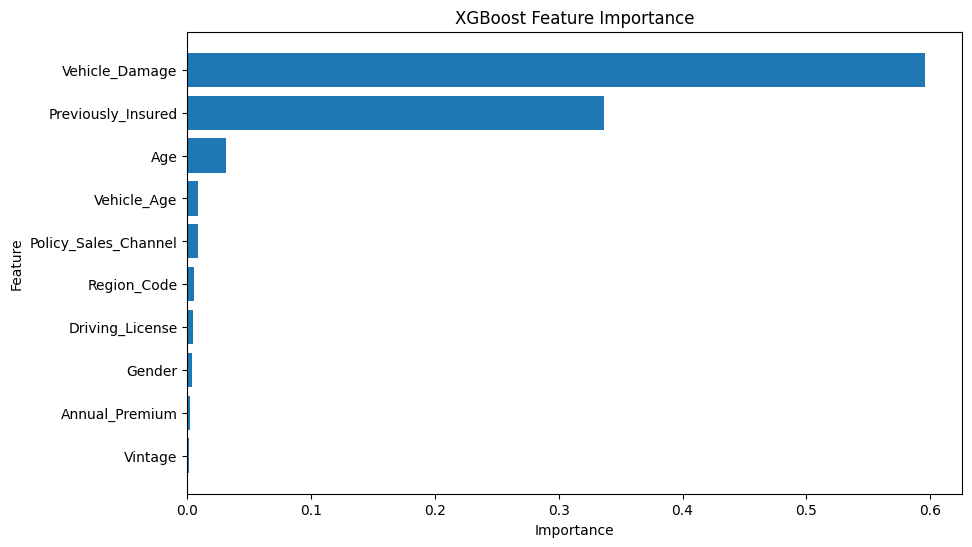

In [26]:

# ========================================
# 27. XGBoost Feature Importance 분석
# ========================================

# 최종 모델의 피처 중요도 가져오기
importances = final_model.feature_importances_

# 변수명 가져오기
feature_names = X_train_final.columns

# 피처 중요도를 DataFrame으로 만들기
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importances
})

# 중요도가 높은 순서대로 정렬
importance_df = importance_df.sort_values(
    by='Importance',
    ascending=False
)

# 중요도 표 출력
display(importance_df)

# 그래프 생성
plt.figure(figsize=(10, 6))

plt.barh(
    importance_df['Feature'],
    importance_df['Importance']
)

plt.title('XGBoost Feature Importance')
plt.xlabel('Importance')
plt.ylabel('Feature')

# 가장 중요한 변수가 위쪽에 오도록 설정
plt.gca().invert_yaxis()

plt.show()


In [27]:

# ========================================
# 28. 전체 데이터로 제출용 모델 학습
# ========================================

# 전체 학습 데이터 전처리
train_all = train.copy()

train_all['Gender'] = train_all['Gender'].map(gender_map)
train_all['Vehicle_Age'] = train_all['Vehicle_Age'].map(vehicle_age_map)
train_all['Vehicle_Damage'] = train_all['Vehicle_Damage'].map(damage_map)

# 전체 학습 데이터의 X, y 분리
X_all = train_all.drop(columns=['id', 'Response'])
y_all = train_all['Response']

# 최종 제출용 모델 생성
submission_model = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

# 전체 학습 데이터로 모델 재학습
submission_model.fit(X_all, y_all)

print('전체 학습 데이터 크기:', X_all.shape)
print('제출용 모델 학습 완료!')


전체 학습 데이터 크기: (381109, 10)
제출용 모델 학습 완료!


In [28]:

# ========================================
# 29. submission.csv 생성
# ========================================

# 공식 Test 데이터에서 id 제외
X_test = test_pre.drop(columns=['id'])

# 학습 데이터와 컬럼 순서 일치시키기
X_test = X_test[X_all.columns]

# 보험 관심 확률 예측
test_probability = submission_model.predict_proba(X_test)[:, 1]

# 제출 파일 생성
submission = pd.DataFrame({
    'id': test['id'],
    'Response': test_probability
})

# 파일 저장
submission.to_csv('submission.csv', index=False)

# 결과 확인
print('제출 파일 크기:', submission.shape)
print('결측치:', submission.isnull().sum().sum())
print('예측 확률 범위:', submission['Response'].min(), '~', submission['Response'].max())

display(submission.head())


제출 파일 크기: (127037, 2)
결측치: 0
예측 확률 범위: 0.00016474641 ~ 0.6244567


,id,Response
0,381110,0.000651
1,381111,0.319415
2,381112,0.303778
3,381113,0.010866
4,381114,0.001011


In [29]:

# ========================================
# 30. 실행 환경 및 라이브러리 버전
# ========================================

import sys
import sklearn
import xgboost

print('Python:', sys.version.split()[0])
print('pandas:', pd.__version__)
print('numpy:', np.__version__)
print('matplotlib:', plt.matplotlib.__version__)
print('seaborn:', sns.__version__)
print('scikit-learn:', sklearn.__version__)
print('xgboost:', xgboost.__version__)
print('Random State: 42')


Python: 3.10.11
pandas: 1.5.3
numpy: 1.23.5
matplotlib: 3.6.3
seaborn: 0.12.2
scikit-learn: 1.0.2
xgboost: 1.7.6
Random State: 42


In [30]:

# ========================================
# 31. submission.csv 최종 검증
# ========================================

# 제출 데이터의 구조 확인
print('Submission 크기:', submission.shape)

# 컬럼 확인
print('컬럼:', submission.columns.tolist())

# 결측치 및 중복 ID 확인
print('결측치:', submission.isnull().sum().sum())
print('중복 ID:', submission['id'].duplicated().sum())

# 원본 Test와 ID 순서 일치 여부
print(
    'Test ID 일치:',
    submission['id'].reset_index(drop=True).equals(
        test['id'].reset_index(drop=True)
    )
)

# 예측 확률이 0~1 범위에 있는지 확인
print(
    '확률 범위 정상:',
    submission['Response'].between(0, 1).all()
)

# 저장된 CSV 다시 불러오기
submission_check = pd.read_csv('submission.csv')

print(
    '저장된 파일 크기:',
    submission_check.shape
)

display(submission_check.head())


Submission 크기: (127037, 2)
컬럼: ['id', 'Response']
결측치: 0
중복 ID: 0
Test ID 일치: True
확률 범위 정상: True
저장된 파일 크기: (127037, 2)


,id,Response
0,381110,0.000651
1,381111,0.319415
2,381112,0.303778
3,381113,0.010866
4,381114,0.001011


In [31]:

# ========================================
# STEP 34. 판매 채널별 보험 관심률 분석
# ========================================

# 학습 데이터에서 판매 채널별 통계 계산
channel_df = train_data.groupby(
    'Policy_Sales_Channel'
)['Response'].agg(
    ['count', 'sum', 'mean']
).reset_index()

# 컬럼명 변경
channel_df.columns = [
    'Policy_Sales_Channel',
    'Customer_Count',
    'Interested_Count',
    'Interest_Rate'
]

# 관심률을 백분율로 변환
channel_df['Interest_Rate'] = (
    channel_df['Interest_Rate'] * 100
)

# 고객 수가 많은 채널부터 정렬
channel_df = channel_df.sort_values(
    by='Customer_Count',
    ascending=False
)

# 상위 15개 채널 출력
display(channel_df.head(15))

# 채널 코드 개수 확인
print('전체 판매 채널 수:', len(channel_df))


,Policy_Sales_Channel,Customer_Count,Interested_Count,Interest_Rate
141,152.0,80910,2282,2.820418
24,26.0,47863,9577,20.009193
117,124.0,44406,8437,18.999685
149,160.0,12985,280,2.156334
145,156.0,6361,1347,21.175916
116,122.0,5927,1038,17.513076
146,157.0,4078,1096,26.875920
143,154.0,3590,873,24.317549
140,151.0,2319,83,3.579129
150,163.0,1715,518,30.204082


전체 판매 채널 수: 151


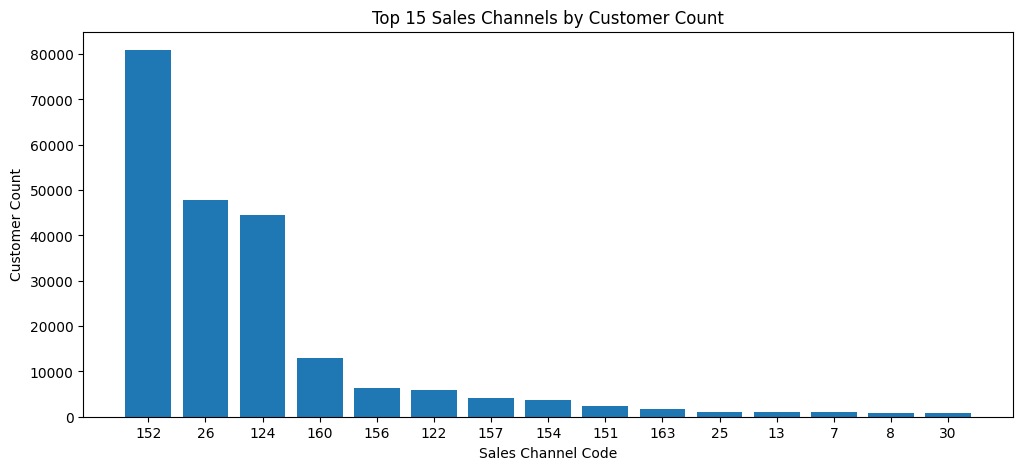

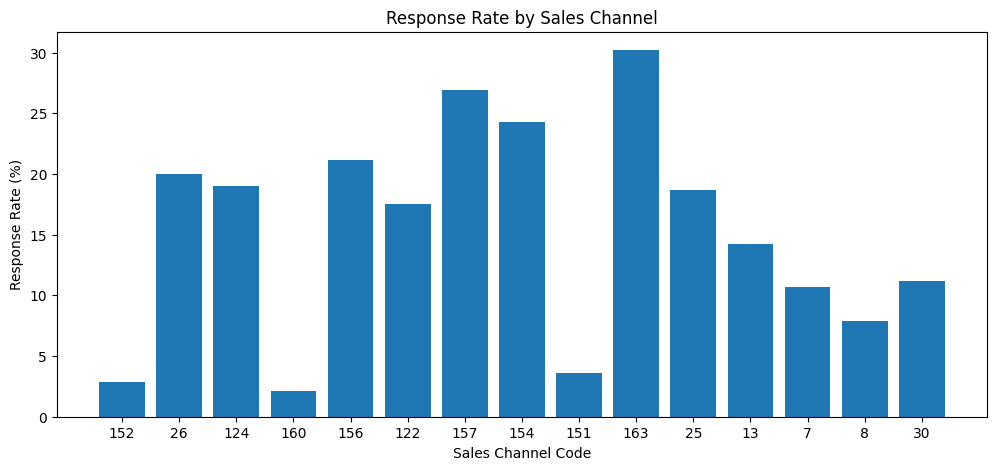

In [32]:

# ========================================
# 35. 판매 채널 상위 15개 시각화
# ========================================

# 고객 수가 가장 많은 15개 채널
top_channels = channel_df.head(15).copy()

# 채널 코드를 문자열로 변경 (그래프 표시용)
top_channels['Channel'] = (
    top_channels['Policy_Sales_Channel'].astype(int).astype(str)
)

# 고객 수 그래프
plt.figure(figsize=(12, 5))

plt.bar(
    top_channels['Channel'],
    top_channels['Customer_Count']
)

plt.title('Top 15 Sales Channels by Customer Count')
plt.xlabel('Sales Channel Code')
plt.ylabel('Customer Count')
plt.show()

# 채널별 관심률 그래프
plt.figure(figsize=(12, 5))

plt.bar(
    top_channels['Channel'],
    top_channels['Interest_Rate']
)

plt.title('Response Rate by Sales Channel')
plt.xlabel('Sales Channel Code')
plt.ylabel('Response Rate (%)')
plt.show()


In [33]:

# ========================================
# 36. 관심률 높은 판매 채널 확인
# ========================================

# 고객이 100명 이상인 채널만 선택
channel_filtered = channel_df[
    channel_df['Customer_Count'] >= 100
]

# 관심률이 높은 순서대로 정렬
channel_rank = channel_filtered.sort_values(
    by='Interest_Rate',
    ascending=False
)

# 상위 15개 출력
display(channel_rank.head(15))


,Policy_Sales_Channel,Customer_Count,Interested_Count,Interest_Rate
144,155.0,748,238,31.818182
150,163.0,1715,518,30.204082
2,3.0,310,93,30.000000
146,157.0,4078,1096,26.875920
139,150.0,189,48,25.396825
129,136.0,112,28,25.000000
147,158.0,298,74,24.832215
29,31.0,401,98,24.438903
143,154.0,3590,873,24.317549
3,4.0,315,67,21.269841


In [34]:

# ========================================
# 37. 판매 채널 및 지역 코드 One-Hot Encoding
# ========================================

# 원본 입력 데이터 복사
X_train_ohe = X_train.copy()
X_valid_ohe = X_valid.copy()

# 범주형 코드로 처리할 컬럼
code_cols = ['Policy_Sales_Channel', 'Region_Code']

# 숫자형 코드를 문자열로 변환
for col in code_cols:
    X_train_ohe[col] = X_train_ohe[col].astype(str)
    X_valid_ohe[col] = X_valid_ohe[col].astype(str)

# One-Hot Encoding 적용
X_train_ohe = pd.get_dummies(
    X_train_ohe,
    columns=code_cols,
    dtype=int
)

X_valid_ohe = pd.get_dummies(
    X_valid_ohe,
    columns=code_cols,
    dtype=int
)

# Validation 컬럼을 Train 컬럼과 일치
X_valid_ohe = X_valid_ohe.reindex(
    columns=X_train_ohe.columns,
    fill_value=0
)

# 데이터 크기 확인
print('기존 Train:', X_train.shape)
print('One-Hot Train:', X_train_ohe.shape)

print('기존 Validation:', X_valid.shape)
print('One-Hot Validation:', X_valid_ohe.shape)


기존 Train: (228665, 10)
One-Hot Train: (228665, 212)
기존 Validation: (76222, 10)
One-Hot Validation: (76222, 212)


In [35]:

# ========================================
# 38. One-Hot Encoding XGBoost 모델
# ========================================

# 기존 모델과 동일한 설정
xgb_ohe = XGBClassifier(
    n_estimators=100,
    max_depth=5,
    learning_rate=0.1,
    random_state=42,
    eval_metric='logloss',
    n_jobs=-1
)

# One-Hot Encoding 데이터로 학습
xgb_ohe.fit(X_train_ohe, y_train)

# 학습 데이터 예측 확률
ohe_train_proba = xgb_ohe.predict_proba(X_train_ohe)[:, 1]

# 검증 데이터 예측 확률
ohe_valid_proba = xgb_ohe.predict_proba(X_valid_ohe)[:, 1]

# ROC-AUC 계산
ohe_train_auc = roc_auc_score(y_train, ohe_train_proba)
ohe_valid_auc = roc_auc_score(y_valid, ohe_valid_proba)

# 기존 모델과 비교
print('기존 XGBoost Validation ROC-AUC:', round(xgb_valid_auc, 6))
print('One-Hot XGBoost Validation ROC-AUC:', round(ohe_valid_auc, 6))
print('ROC-AUC 변화:', round(ohe_valid_auc - xgb_valid_auc, 6))
print('One-Hot 모델 Train ROC-AUC:', round(ohe_train_auc, 6))


기존 XGBoost Validation ROC-AUC: 0.857758
One-Hot XGBoost Validation ROC-AUC: 0.856416
ROC-AUC 변화: -0.001341
One-Hot 모델 Train ROC-AUC: 0.861264


In [36]:

# ========================================
# 39. LightGBM 모델 학습
# ========================================

# LightGBM 불러오기
from lightgbm import LGBMClassifier

# LightGBM 모델 생성
lgbm_model = LGBMClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=5,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# 기존 학습 데이터로 학습
lgbm_model.fit(X_train, y_train)

# Train 예측 확률
lgbm_train_proba = lgbm_model.predict_proba(X_train)[:, 1]

# Validation 예측 확률
lgbm_valid_proba = lgbm_model.predict_proba(X_valid)[:, 1]

# ROC-AUC 계산
lgbm_train_auc = roc_auc_score(y_train, lgbm_train_proba)
lgbm_valid_auc = roc_auc_score(y_valid, lgbm_valid_proba)

# 결과 출력
print('LightGBM Train ROC-AUC:', round(lgbm_train_auc, 6))
print('LightGBM Validation ROC-AUC:', round(lgbm_valid_auc, 6))
print('ROC-AUC 차이:', round(lgbm_train_auc - lgbm_valid_auc, 6))

# XGBoost와 비교
print()
print('XGBoost Validation ROC-AUC:', round(xgb_valid_auc, 6))
print('LightGBM Validation ROC-AUC:', round(lgbm_valid_auc, 6))
print('성능 변화:', round(lgbm_valid_auc - xgb_valid_auc, 6))


LightGBM Train ROC-AUC: 0.862079
LightGBM Validation ROC-AUC: 0.857888
ROC-AUC 차이: 0.00419

XGBoost Validation ROC-AUC: 0.857758
LightGBM Validation ROC-AUC: 0.857888
성능 변화: 0.000131


In [37]:

# ========================================
# 40. LightGBM 임계값별 F1-score
# ========================================

# 비교할 임계값
thresholds = [0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]

# 결과 저장
lgbm_f1_results = []

for threshold in thresholds:

    # 임계값에 따라 0 또는 1로 분류
    pred = (lgbm_valid_proba >= threshold).astype(int)

    # 성능 계산
    precision = precision_score(y_valid, pred, zero_division=0)
    recall = recall_score(y_valid, pred, zero_division=0)
    f1 = f1_score(y_valid, pred, zero_division=0)

    # 결과 저장
    lgbm_f1_results.append([
        threshold,
        precision,
        recall,
        f1
    ])

# 결과표 생성
lgbm_f1_df = pd.DataFrame(
    lgbm_f1_results,
    columns=['Threshold', 'Precision', 'Recall', 'F1']
)

display(lgbm_f1_df)

# 가장 높은 F1-score 확인
best_row = lgbm_f1_df.loc[lgbm_f1_df['F1'].idxmax()]

print('최고 F1-score:', round(best_row['F1'], 6))
print('최적 임계값 후보:', best_row['Threshold'])


,Threshold,Precision,Recall,F1
0,0.10,0.269907,0.954614,0.420829
1,0.15,0.293336,0.891030,0.441369
2,0.20,0.313378,0.818668,0.453255
3,0.25,0.336667,0.724256,0.459662
4,0.30,0.365875,0.545601,0.438018
5,0.40,0.442759,0.103083,0.167231
6,0.50,0.645833,0.003318,0.006603


최고 F1-score: 0.459662
최적 임계값 후보: 0.25


In [38]:

# ========================================
# 41. XGBoost vs LightGBM 성능 비교
# ========================================

# 동일한 임계값 적용
threshold = 0.25

# XGBoost 예측 결과
xgb_pred_025 = (xgb_valid_proba >= threshold).astype(int)

# LightGBM 예측 결과
lgbm_pred_025 = (lgbm_valid_proba >= threshold).astype(int)

# 모델별 성능 비교
comparison_df = pd.DataFrame({
    'Model': ['XGBoost', 'LightGBM'],

    'ROC_AUC': [
        roc_auc_score(y_valid, xgb_valid_proba),
        roc_auc_score(y_valid, lgbm_valid_proba)
    ],

    'Precision': [
        precision_score(y_valid, xgb_pred_025),
        precision_score(y_valid, lgbm_pred_025)
    ],

    'Recall': [
        recall_score(y_valid, xgb_pred_025),
        recall_score(y_valid, lgbm_pred_025)
    ],

    'F1_Score': [
        f1_score(y_valid, xgb_pred_025),
        f1_score(y_valid, lgbm_pred_025)
    ]
})

# 비교 결과 출력
display(comparison_df.round(6))


,Model,ROC_AUC,Precision,Recall,F1_Score
0,XGBoost,0.857758,0.335847,0.729501,0.459945
1,LightGBM,0.857888,0.336667,0.724256,0.459662


In [39]:

# ========================================
# 42. 모델별 F1-score 최적 임계값 비교
# ========================================

# 비교할 임계값
threshold_list = np.arange(0.10, 0.51, 0.01)

# 비교할 모델의 Validation 예측 확률
probability_dict = {
    'XGBoost': xgb_valid_proba,
    'LightGBM': lgbm_valid_proba
}

# 결과 저장
best_f1_results = []

for model_name, probabilities in probability_dict.items():

    # 각 임계값별 결과 저장
    scores = []

    for threshold in threshold_list:

        # 관심 고객 예측
        pred = (probabilities >= threshold).astype(int)

        # F1-score 계산
        score = f1_score(y_valid, pred, zero_division=0)

        # 결과 저장
        scores.append([threshold, score])

    # DataFrame 생성
    temp_df = pd.DataFrame(
        scores,
        columns=['Threshold', 'F1_Score']
    )

    # 가장 높은 F1-score의 행 선택
    best_row = temp_df.loc[temp_df['F1_Score'].idxmax()]

    # 최적 결과 저장
    best_f1_results.append([
        model_name,
        best_row['Threshold'],
        best_row['F1_Score']
    ])

# 최종 비교표
best_f1_df = pd.DataFrame(
    best_f1_results,
    columns=['Model', 'Best_Threshold', 'Best_F1']
)

display(best_f1_df.round(6))


,Model,Best_Threshold,Best_F1
0,XGBoost,0.25,0.459945
1,LightGBM,0.24,0.460151


In [40]:

# ========================================
# 43. LightGBM 하이퍼파라미터 튜닝
# ========================================

from sklearn.model_selection import GridSearchCV
from lightgbm import LGBMClassifier

# 튜닝할 LightGBM 모델 생성
lgbm_tuning = LGBMClassifier(
    random_state=42,
    n_jobs=4,
    verbosity=-1
)

# 탐색할 하이퍼파라미터
param_grid_lgbm = {
    'n_estimators': [100, 200],
    'learning_rate': [0.05, 0.1],
    'num_leaves': [15, 31],
    'max_depth': [5]
}

# GridSearchCV 생성
lgbm_grid = GridSearchCV(
    estimator=lgbm_tuning,
    param_grid=param_grid_lgbm,
    scoring='roc_auc',
    cv=3,
    n_jobs=1,
    verbose=1
)

# 학습 데이터로만 튜닝
lgbm_grid.fit(X_train, y_train)

# 최적 파라미터 출력
print('최적 파라미터:', lgbm_grid.best_params_)
print('최적 CV ROC-AUC:', round(lgbm_grid.best_score_, 6))

# 최적 모델 저장
lgbm_best = lgbm_grid.best_estimator_

# Validation 예측 확률
lgbm_best_proba = lgbm_best.predict_proba(X_valid)[:, 1]

# Validation ROC-AUC 계산
lgbm_best_auc = roc_auc_score(y_valid, lgbm_best_proba)

print('튜닝 후 Validation ROC-AUC:', round(lgbm_best_auc, 6))
print('튜닝 전 Validation ROC-AUC:', round(lgbm_valid_auc, 6))
print('ROC-AUC 변화:', round(lgbm_best_auc - lgbm_valid_auc, 6))


Fitting 3 folds for each of 8 candidates, totalling 24 fits
최적 파라미터: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 200, 'num_leaves': 31}
최적 CV ROC-AUC: 0.856478
튜닝 후 Validation ROC-AUC: 0.858352
튜닝 전 Validation ROC-AUC: 0.857888
ROC-AUC 변화: 0.000464


In [41]:

# ========================================
# 44. 튜닝된 LightGBM F1-score 분석
# ========================================

# 0.10부터 0.50까지 임계값 비교
threshold_list = np.arange(0.10, 0.51, 0.01)

# 결과 저장
lgbm_tuned_results = []

for threshold in threshold_list:

    # 임계값에 따른 분류
    pred = (lgbm_best_proba >= threshold).astype(int)

    # F1-score 계산
    f1 = f1_score(y_valid, pred, zero_division=0)

    lgbm_tuned_results.append([
        round(threshold, 2),
        f1
    ])

# 결과표 생성
lgbm_tuned_df = pd.DataFrame(
    lgbm_tuned_results,
    columns=['Threshold', 'F1_Score']
)

# 가장 높은 F1-score 선택
best_f1_row = lgbm_tuned_df.loc[
    lgbm_tuned_df['F1_Score'].idxmax()
]

print('최적 임계값 후보:', best_f1_row['Threshold'])
print('최고 F1-score:', round(best_f1_row['F1_Score'], 6))


최적 임계값 후보: 0.22
최고 F1-score: 0.459758


In [42]:

# ========================================
# 45. LightGBM n_estimators 추가 실험
# ========================================

# 비교할 트리 개수
n_estimators_list = [100, 200, 300, 400, 500]

# 결과 저장
lgbm_extra_results = []

for n in n_estimators_list:

    # LightGBM 모델 생성
    model = LGBMClassifier(
        n_estimators=n,
        learning_rate=0.1,
        max_depth=5,
        num_leaves=31,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    # 모델 학습
    model.fit(X_train, y_train)

    # Train 예측 확률
    train_proba = model.predict_proba(X_train)[:, 1]

    # Validation 예측 확률
    valid_proba = model.predict_proba(X_valid)[:, 1]

    # ROC-AUC 계산
    train_score = roc_auc_score(y_train, train_proba)
    valid_score = roc_auc_score(y_valid, valid_proba)

    # 결과 저장
    lgbm_extra_results.append([
        n,
        train_score,
        valid_score,
        train_score - valid_score
    ])

# 결과표 생성
lgbm_extra_df = pd.DataFrame(
    lgbm_extra_results,
    columns=[
        'n_estimators',
        'Train_AUC',
        'Validation_AUC',
        'AUC_Gap'
    ]
)

display(lgbm_extra_df.round(6))

# 가장 높은 Validation ROC-AUC 확인
best_row = lgbm_extra_df.loc[
    lgbm_extra_df['Validation_AUC'].idxmax()
]

print('가장 좋은 n_estimators:', int(best_row['n_estimators']))
print('최고 Validation ROC-AUC:', round(best_row['Validation_AUC'], 6))


,n_estimators,Train_AUC,Validation_AUC,AUC_Gap
0,100,0.862079,0.857888,0.004190
1,200,0.869492,0.858352,0.011140
2,300,0.875211,0.857992,0.017219
3,400,0.880303,0.857398,0.022905
4,500,0.884883,0.856755,0.028128


가장 좋은 n_estimators: 200
최고 Validation ROC-AUC: 0.858352


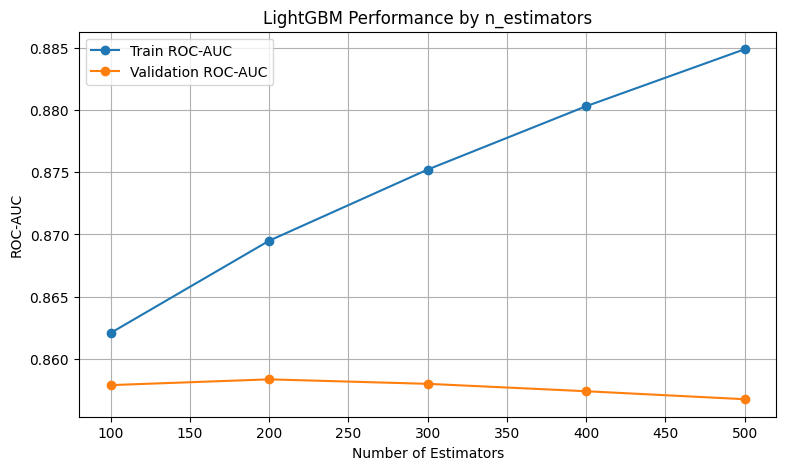

In [43]:

# ========================================
# 46. 트리 개수별 ROC-AUC 시각화
# ========================================

plt.figure(figsize=(9, 5))

plt.plot(
    lgbm_extra_df['n_estimators'],
    lgbm_extra_df['Train_AUC'],
    marker='o',
    label='Train ROC-AUC'
)

plt.plot(
    lgbm_extra_df['n_estimators'],
    lgbm_extra_df['Validation_AUC'],
    marker='o',
    label='Validation ROC-AUC'
)

plt.title('LightGBM Performance by n_estimators')
plt.xlabel('Number of Estimators')
plt.ylabel('ROC-AUC')
plt.legend()
plt.grid(True)
plt.show()


In [44]:

# ========================================
# 47. 새로운 변수 생성
# ========================================

# 기존 데이터 복사
X_train_fe = X_train.copy()
X_valid_fe = X_valid.copy()

# 보험 가입 여부와 차량 손상 여부 조합
X_train_fe['Insured_Damage'] = (
    X_train_fe['Previously_Insured'] * 2
    + X_train_fe['Vehicle_Damage']
)

X_valid_fe['Insured_Damage'] = (
    X_valid_fe['Previously_Insured'] * 2
    + X_valid_fe['Vehicle_Damage']
)

# 생성한 변수의 값 확인
print('Train 조합 변수 분포')
print(X_train_fe['Insured_Damage'].value_counts().sort_index())

print('Validation 조합 변수 분포')
print(X_valid_fe['Insured_Damage'].value_counts().sort_index())


Train 조합 변수 분포
0     14348
1    109513
2     98847
3      5957
Name: Insured_Damage, dtype: int64
Validation 조합 변수 분포
0     4798
1    36551
2    32935
3     1938
Name: Insured_Damage, dtype: int64


In [45]:

# ========================================
# 48. 피처 엔지니어링 LightGBM
# ========================================

# 새로운 변수를 추가한 LightGBM
lgbm_fe = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    num_leaves=31,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

# 학습
lgbm_fe.fit(X_train_fe, y_train)

# Validation 예측 확률
lgbm_fe_proba = lgbm_fe.predict_proba(X_valid_fe)[:, 1]

# ROC-AUC 평가
lgbm_fe_auc = roc_auc_score(y_valid, lgbm_fe_proba)

# 기존 모델과 성능 비교
print('기존 LightGBM ROC-AUC:', round(lgbm_best_auc, 6))
print('FE LightGBM ROC-AUC:', round(lgbm_fe_auc, 6))
print('ROC-AUC 변화:', round(lgbm_fe_auc - lgbm_best_auc, 6))


기존 LightGBM ROC-AUC: 0.858352
FE LightGBM ROC-AUC: 0.85815
ROC-AUC 변화: -0.000202


In [46]:

# ========================================
# 49. LightGBM min_child_samples 실험
# ========================================

# 비교할 값
min_child_list = [20, 50, 100, 200]

# 결과 저장
child_results = []

for min_child in min_child_list:

    # 모델 생성
    model = LGBMClassifier(
        n_estimators=200,
        learning_rate=0.1,
        max_depth=5,
        num_leaves=31,
        min_child_samples=min_child,
        random_state=42,
        n_jobs=-1,
        verbosity=-1
    )

    # 모델 학습
    model.fit(X_train, y_train)

    # Train과 Validation 예측 확률
    train_probability = model.predict_proba(X_train)[:, 1]
    valid_probability = model.predict_proba(X_valid)[:, 1]

    # ROC-AUC 계산
    train_auc_score = roc_auc_score(y_train, train_probability)
    valid_auc_score = roc_auc_score(y_valid, valid_probability)

    # 결과 저장
    child_results.append([
        min_child,
        train_auc_score,
        valid_auc_score,
        train_auc_score - valid_auc_score
    ])

# 결과표 생성
child_df = pd.DataFrame(
    child_results,
    columns=[
        'min_child_samples',
        'Train_AUC',
        'Validation_AUC',
        'AUC_Gap'
    ]
)

display(child_df.round(6))

# 최고 검증 성능 확인
best_child = child_df.loc[child_df['Validation_AUC'].idxmax()]

print('최고 min_child_samples:', int(best_child['min_child_samples']))
print('최고 Validation ROC-AUC:', round(best_child['Validation_AUC'], 6))


,min_child_samples,Train_AUC,Validation_AUC,AUC_Gap
0,20,0.869492,0.858352,0.011140
1,50,0.869007,0.858396,0.010611
2,100,0.867735,0.858190,0.009544
3,200,0.866698,0.858420,0.008278


최고 min_child_samples: 200
최고 Validation ROC-AUC: 0.85842


In [47]:

# 최종 LightGBM 설정으로 학습
lgbm_final_candidate = LGBMClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=5,
    num_leaves=31,
    min_child_samples=200,
    random_state=42,
    n_jobs=-1,
    verbosity=-1
)

lgbm_final_candidate.fit(X_train, y_train)

# Validation 예측 확률
final_valid_proba = lgbm_final_candidate.predict_proba(X_valid)[:, 1]

# 임계값별 F1-score 비교
f1_results = []

for threshold in np.arange(0.10, 0.51, 0.01):
    pred = (final_valid_proba >= threshold).astype(int)
    score = f1_score(y_valid, pred, zero_division=0)

    f1_results.append([round(threshold, 2), score])

f1_df = pd.DataFrame(
    f1_results,
    columns=['Threshold', 'F1']
)

best_f1 = f1_df.loc[f1_df['F1'].idxmax()]

print('Validation ROC-AUC:', round(roc_auc_score(y_valid, final_valid_proba), 6))
print('최고 F1-score:', round(best_f1['F1'], 6))
print('최적 임계값:', best_f1['Threshold'])


Validation ROC-AUC: 0.85842
최고 F1-score: 0.458943
최적 임계값: 0.23


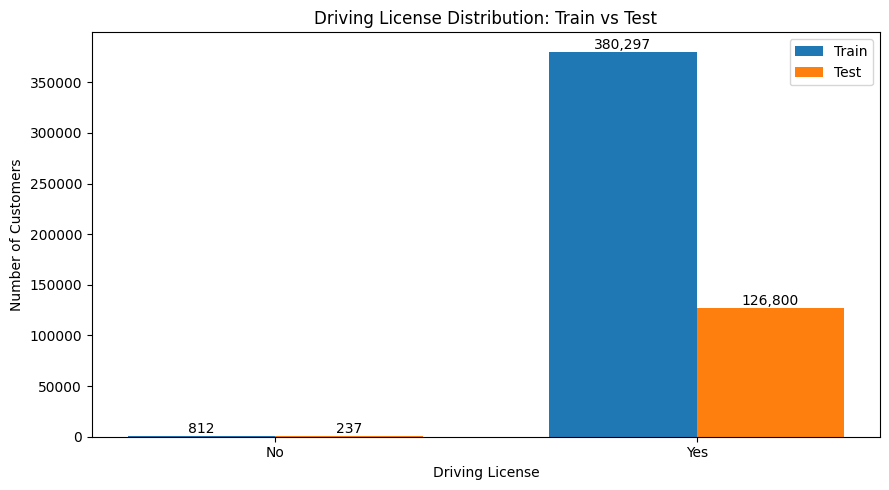

In [48]:

# Train과 Test의 운전면허 보유 여부별 고객 수 계산
train_license = train['Driving_License'].value_counts().reindex([0, 1], fill_value=0)
test_license = test['Driving_License'].value_counts().reindex([0, 1], fill_value=0)

# 그래프에 사용할 데이터
labels = ['No', 'Yes']
x = np.arange(len(labels))
width = 0.35

# 그래프 생성
plt.figure(figsize=(9, 5))

bars1 = plt.bar(
    x - width / 2,
    train_license.values,
    width,
    label='Train'
)

bars2 = plt.bar(
    x + width / 2,
    test_license.values,
    width,
    label='Test'
)

# 막대 위 고객 수 표시
for bars in [bars1, bars2]:
    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f'{int(bar.get_height()):,}',
            ha='center',
            va='bottom'
        )

plt.title('Driving License Distribution: Train vs Test')
plt.xlabel('Driving License')
plt.ylabel('Number of Customers')
plt.xticks(x, labels)
plt.legend()
plt.tight_layout()
plt.show()


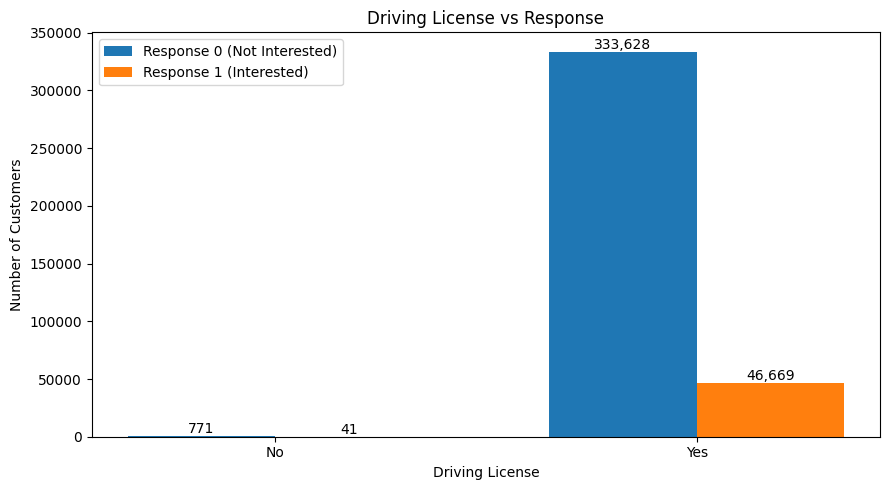

운전면허 보유 여부별 보험 관심률 (%)
Driving_License
No      5.05
Yes    12.27
Name: Response, dtype: float64


In [49]:

# 운전면허 보유 여부에 따른 Response별 고객 수
license_response = pd.crosstab(
    train['Driving_License'],
    train['Response']
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

# 그래프에 사용할 데이터
labels = ['No', 'Yes']
x = np.arange(len(labels))
width = 0.35

plt.figure(figsize=(9, 5))

bars1 = plt.bar(
    x - width / 2,
    license_response[0],
    width,
    label='Response 0 (Not Interested)'
)

bars2 = plt.bar(
    x + width / 2,
    license_response[1],
    width,
    label='Response 1 (Interested)'
)

# 막대 위 고객 수 표시
for bars in [bars1, bars2]:
    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            f'{int(bar.get_height()):,}',
            ha='center',
            va='bottom'
        )

plt.title('Driving License vs Response')
plt.xlabel('Driving License')
plt.ylabel('Number of Customers')
plt.xticks(x, labels)
plt.legend()
plt.tight_layout()
plt.show()

# 운전면허 보유 여부별 보험 관심률 확인
response_rate = train.groupby('Driving_License')['Response'].mean() * 100

print('운전면허 보유 여부별 보험 관심률 (%)')
print(response_rate.rename(index={0: 'No', 1: 'Yes'}).round(2))


전처리 전 고객 수
No        488
Yes    228177
Name: Driving_License, dtype: int64

전처리 후 고객 수
No        488
Yes    228177
Name: Driving_License, dtype: int64

전처리 전후 값이 동일한가? True


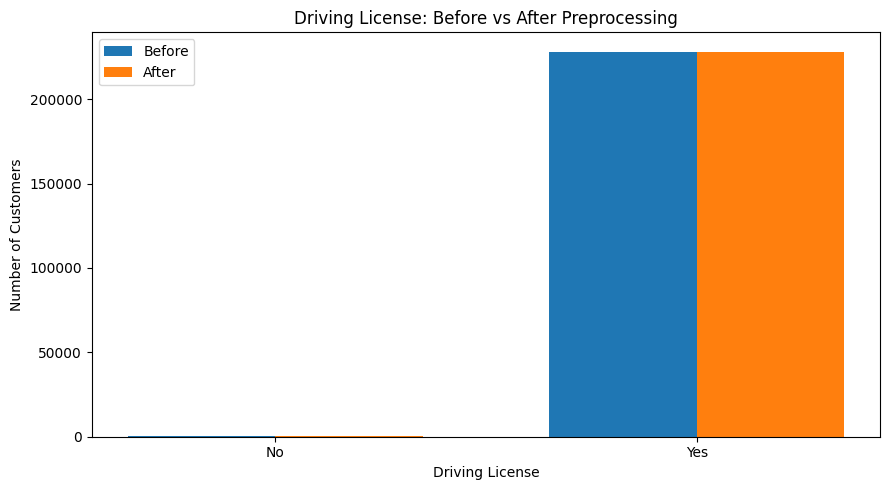

In [50]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 원본 Train과 전처리된 Train 비교
# train_data는 원본을 분할한 데이터
# train_pre는 전처리한 데이터
before = train_data['Driving_License'].value_counts().reindex([0, 1], fill_value=0)
after = train_pre['Driving_License'].value_counts().reindex([0, 1], fill_value=0)

print("전처리 전 고객 수")
print(before.rename(index={0: 'No', 1: 'Yes'}))

print("\n전처리 후 고객 수")
print(after.rename(index={0: 'No', 1: 'Yes'}))

print("\n전처리 전후 값이 동일한가?",
      train_data['Driving_License'].equals(train_pre['Driving_License']))

# 막대그래프
labels = ['No', 'Yes']
x = np.arange(2)
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(x - width/2, before.values, width, label='Before')
plt.bar(x + width/2, after.values, width, label='After')

plt.title('Driving License: Before vs After Preprocessing')
plt.xlabel('Driving License')
plt.ylabel('Number of Customers')
plt.xticks(x, labels)
plt.legend()
plt.tight_layout()
plt.show()


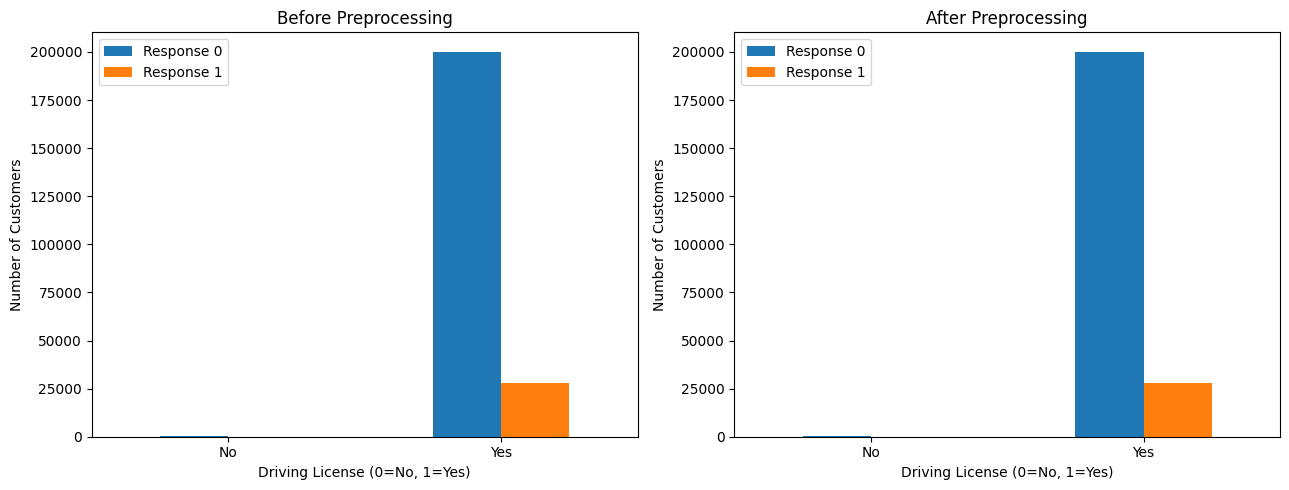

Driving License별 보험 관심률 (%)
Driving_License
No      5.53
Yes    12.27
Name: Response, dtype: float64


In [51]:

# 전처리 전 Response 분포
before_response = pd.crosstab(
    train_data['Driving_License'],
    train_data['Response']
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

# 전처리 후 Response 분포
after_response = pd.crosstab(
    train_pre['Driving_License'],
    train_pre['Response']
).reindex(index=[0, 1], columns=[0, 1], fill_value=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

before_response.plot(kind='bar', ax=axes[0])
axes[0].set_title('Before Preprocessing')
axes[0].set_xlabel('Driving License (0=No, 1=Yes)')
axes[0].set_ylabel('Number of Customers')
axes[0].set_xticklabels(['No', 'Yes'], rotation=0)
axes[0].legend(['Response 0', 'Response 1'])

after_response.plot(kind='bar', ax=axes[1])
axes[1].set_title('After Preprocessing')
axes[1].set_xlabel('Driving License (0=No, 1=Yes)')
axes[1].set_ylabel('Number of Customers')
axes[1].set_xticklabels(['No', 'Yes'], rotation=0)
axes[1].legend(['Response 0', 'Response 1'])

plt.tight_layout()
plt.show()

# 관심률까지 확인
print("Driving License별 보험 관심률 (%)")
print(
    train_data.groupby('Driving_License')['Response']
    .mean()
    .mul(100)
    .rename(index={0: 'No', 1: 'Yes'})
    .round(2)
)


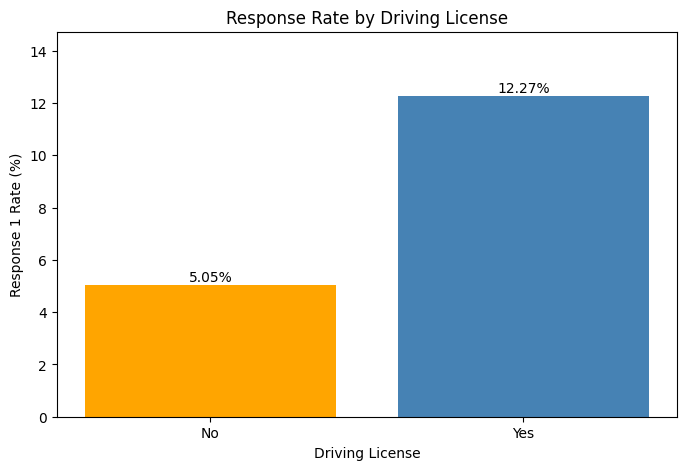

Driving_License
0     5.05
1    12.27
Name: Response, dtype: float64


In [52]:
# 운전면허 여부별 보험 관심률 계산
license_rate = (
    train.groupby('Driving_License')['Response']
    .mean() * 100
)

license_rate = license_rate.reindex([0, 1], fill_value=0)

# 그래프 생성
plt.figure(figsize=(8, 5))

bars = plt.bar(
    ['No', 'Yes'],
    license_rate.values,
    color=['orange', 'steelblue']
)

# 막대 위 관심률 표시
for bar in bars:
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f'{bar.get_height():.2f}%',
        ha='center',
        va='bottom'
    )

plt.title('Response Rate by Driving License')
plt.xlabel('Driving License')
plt.ylabel('Response 1 Rate (%)')
plt.ylim(0, max(1, license_rate.max() * 1.2))
plt.show()

print(license_rate.round(2))

In [53]:

from xgboost import XGBClassifier
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score
import pandas as pd

# 1. XGBoost 기본 모델
xgb_tuning = XGBClassifier(
    random_state=42,
    eval_metric='logloss',
    tree_method='hist',
    n_jobs=4
)

# 2. 탐색할 파라미터 설정
param_dist = {
    'n_estimators': [150, 200, 250, 300, 400],
    'max_depth': [3, 4, 5, 6],
    'learning_rate': [0.03, 0.05, 0.07, 0.1],
    'min_child_weight': [1, 3, 5, 10],
    'subsample': [0.7, 0.8, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
    'reg_lambda': [1, 5, 10]
}

# 3. 교차검증 설정
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# 4. 랜덤 탐색 설정
random_search = RandomizedSearchCV(
    estimator=xgb_tuning,
    param_distributions=param_dist,
    n_iter=20,
    scoring='roc_auc',
    cv=cv,
    random_state=42,
    n_jobs=2,
    verbose=1,
    refit=True
)

# 5. Train 데이터로만 최적화
random_search.fit(X_train, y_train)

# 6. 최적 결과 출력
print('최적 파라미터:', random_search.best_params_)
print('최고 CV ROC-AUC:', round(random_search.best_score_, 6))

# 7. Validation 평가
best_xgb_random = random_search.best_estimator_

valid_proba_random = best_xgb_random.predict_proba(X_valid)[:, 1]

random_valid_auc = roc_auc_score(
    y_valid,
    valid_proba_random
)

print('Validation ROC-AUC:', round(random_valid_auc, 6))
print('기존 XGBoost ROC-AUC:', 0.858165)
print('성능 차이:', round(random_valid_auc - 0.858165, 6))


Fitting 3 folds for each of 20 candidates, totalling 60 fits
최적 파라미터: {'subsample': 0.8, 'reg_lambda': 1, 'n_estimators': 400, 'min_child_weight': 1, 'max_depth': 6, 'learning_rate': 0.03, 'colsample_bytree': 0.7}
최고 CV ROC-AUC: 0.857241
Validation ROC-AUC: 0.858646
기존 XGBoost ROC-AUC: 0.858165
성능 차이: 0.000481


In [54]:

from sklearn.metrics import roc_auc_score, f1_score
import numpy as np

# 추가 튜닝에서 선택된 XGBoost 모델
best_xgb = random_search.best_estimator_

# Validation 예측 확률
valid_proba = best_xgb.predict_proba(X_valid)[:, 1]

# 임계값별 F1-score 비교
best_f1 = 0
best_threshold = 0

for threshold in np.arange(0.10, 0.51, 0.01):
    pred = (valid_proba >= threshold).astype(int)
    score = f1_score(y_valid, pred, zero_division=0)

    if score > best_f1:
        best_f1 = score
        best_threshold = threshold

print('Validation ROC-AUC:', round(roc_auc_score(y_valid, valid_proba), 6))
print('최고 F1-score:', round(best_f1, 6))
print('최적 임계값:', round(best_threshold, 2))


Validation ROC-AUC: 0.858646
최고 F1-score: 0.459705
최적 임계값: 0.24


In [56]:

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# 최신 튜닝 XGBoost의 Validation 예측 확률
proba = random_search.best_estimator_.predict_proba(X_valid)[:, 1]

# F1-score가 가장 높았던 임계값
threshold = 0.24

# 예측 확률을 0과 1로 변환
pred = (proba >= threshold).astype(int)

print('Precision:', round(precision_score(y_valid, pred), 6))
print('Recall:', round(recall_score(y_valid, pred), 6))
print('F1-score:', round(f1_score(y_valid, pred), 6))

print('\nConfusion Matrix')
print(confusion_matrix(y_valid, pred))


Precision: 0.334029
Recall: 0.736994
F1-score: 0.459705

Confusion Matrix
[[53153 13727]
 [ 2457  6885]]


In [ ]:

## 최종 ##

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, f1_score
import numpy as np

# 1. 이전 최적 모델 설정
xgb_model = XGBClassifier(
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.7,
    reg_lambda=1,
    random_state=42,
    eval_metric='logloss',
    tree_method='hist',
    n_jobs=4
)

# 2. 추가로 탐색할 후보
params = {
    'n_estimators': [300, 400, 500],
    'learning_rate': [0.02, 0.03, 0.05],
    'max_depth': [5, 6]
}

# 3. 3-Fold 교차검증
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# 4. GridSearchCV
grid_extra = GridSearchCV(
    xgb_model,
    param_grid=params,
    scoring='roc_auc',
    cv=cv,
    n_jobs=2,
    verbose=1
)

# 5. 학습
grid_extra.fit(X_train, y_train)

# 6. 최적 파라미터 및 CV 점수
print('최적 파라미터:', grid_extra.best_params_)
print('최고 CV ROC-AUC:', grid_extra.best_score_)

# 7. Validation 평가
proba = grid_extra.best_estimator_.predict_proba(X_valid)[:, 1]

auc = roc_auc_score(y_valid, proba)

print('Validation ROC-AUC:', round(auc, 6))

# 8. F1-score 비교
best_f1 = 0
best_threshold = 0

for threshold in np.arange(0.10, 0.51, 0.01):
    pred = (proba >= threshold).astype(int)
    score = f1_score(y_valid, pred)

    if score > best_f1:
        best_f1 = score
        best_threshold = threshold

print('최고 F1-score:', round(best_f1, 6))
print('최적 임계값:', round(best_threshold, 2))


Fitting 3 folds for each of 18 candidates, totalling 54 fits
최적 파라미터: {'learning_rate': 0.03, 'max_depth': 5, 'n_estimators': 500}
최고 CV ROC-AUC: 0.8573720283949613
Validation ROC-AUC: 0.858696
최고 F1-score: 0.460008
최적 임계값: 0.23


In [58]:

from xgboost import XGBClassifier
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import roc_auc_score, f1_score

# 기존 최적 파라미터 유지
xgb_model = XGBClassifier(
    max_depth=5,
    learning_rate=0.03,
    min_child_weight=1,
    subsample=0.8,
    colsample_bytree=0.7,
    reg_lambda=1,
    random_state=42,
    eval_metric='logloss',
    tree_method='hist',
    n_jobs=4
)

# 트리 개수만 변경
params = {
    'n_estimators': [500, 700, 1000]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

grid_1000 = GridSearchCV(
    xgb_model,
    param_grid=params,
    scoring='roc_auc',
    cv=cv,
    n_jobs=2,
    verbose=1
)

grid_1000.fit(X_train, y_train)

print("최적 트리 개수:", grid_1000.best_params_)
print("최고 CV ROC-AUC:", grid_1000.best_score_)

# Validation 평가
proba = grid_1000.best_estimator_.predict_proba(X_valid)[:, 1]

print("Validation ROC-AUC:", roc_auc_score(y_valid, proba))

# 이전에 정한 임계값 0.23으로 F1 평가
pred = (proba >= 0.23).astype(int)

print("F1-score:", f1_score(y_valid, pred))


Fitting 3 folds for each of 3 candidates, totalling 9 fits
최적 트리 개수: {'n_estimators': 500}
최고 CV ROC-AUC: 0.8573720283949613
Validation ROC-AUC: 0.858696237550436
F1-score: 0.46000775293965623
